# 04 Models
Emmanuel: final models and comparison.

In [20]:
import pandas as pd  
import matplotlib.pyplot as plt 
import sys; sys.path.insert(0, '..')

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from src.split import load_split
from src.evaluate import evaluate


In [ ]:
X_train, X_test, y_train, y_test = load_split(
    path="../data/processed/clean.parquet"
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining labels:")
print(y_train.value_counts())

Training set: (188296, 50)
Testing set: (47074, 50)

Training labels:
label
0    107880
1     80416
Name: count, dtype: int64


In [22]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=10000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    result = evaluate(
        model,
        X_test,
        y_test,
        name=name
    )

    results.append(result)

print("All models trained and evaluated.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
All models trained and evaluated.


In [23]:
results_df = pd.DataFrame(results)

comparison = results_df.drop(
    columns=["confusion_matrix"]
).sort_values(
    by="f1",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,model,accuracy,precision,recall,f1,roc_auc
0,Decision Tree,1.0,1.0,1.0000,1.0,1.0
1,Random Forest,1.0,1.0,1.0000,1.0,1.0
2,Logistic Regression,1.0,1.0,0.9999,1.0,1.0


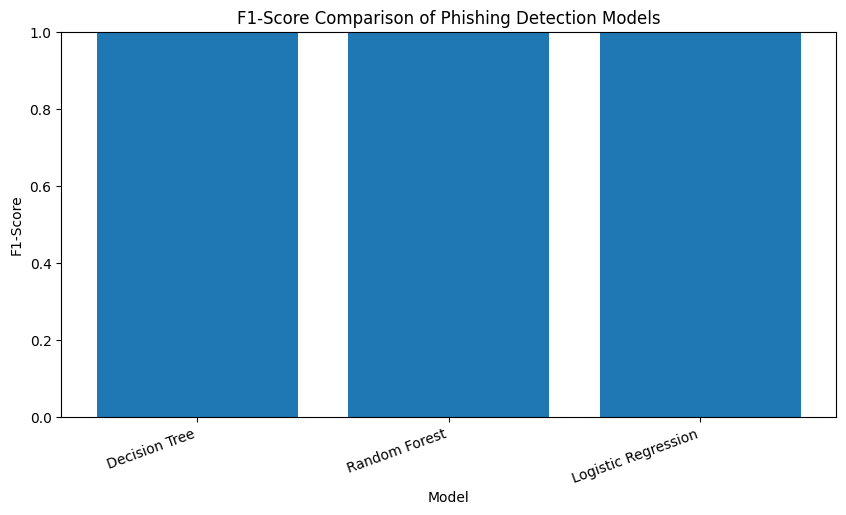

In [24]:
plt.figure(figsize=(10,5))

plt.bar(
    comparison["model"],
    comparison["f1"]
)

plt.title("F1-Score Comparison of Phishing Detection Models")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.ylim(0,1)
plt.xticks(rotation=20, ha="right")
plt.show(close=None, block=None)

In [25]:
for result in results:
    print(f"\n{result['model']} - Confusion Matrix")

    cm = pd.DataFrame(
        result["confusion_matrix"],
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]

    )

    display(cm)


Logistic Regression - Confusion Matrix


,Predicted 0,Predicted 1
Actual 0,26970,0
Actual 1,2,20102



Decision Tree - Confusion Matrix


,Predicted 0,Predicted 1
Actual 0,26970,0
Actual 1,0,20104



Random Forest - Confusion Matrix


,Predicted 0,Predicted 1
Actual 0,26970,0
Actual 1,0,20104
